In [1]:
import sys, os

sys.path.append(os.path.dirname(os.getcwd()))

import h5py
import tqdm
import matplotlib.pyplot as plt

plt.rcParams.update({"mathtext.fontset": "cm"})

import numpy as np
import jax
import jax.numpy as jnp

jax.config.update("jax_enable_x64", True)
jax.config.update("jax_platforms", "cpu")

from flax import nnx
import optax

import shtns
import jaxbind

import models.time_solver as imex
from models.sph_mhd import (
    SphericalMHD,
    dynamical_solver,
    integral,
    kinetic_energy,
)

[SHTns 3.7.5] built Mar 17 2026, 14:03:42, id: avx512,ishioka


In [2]:
eq = SphericalMHD(Ra=100, E=1e-3, radius_ratio=0.35, l_max=31, m_max=7, m_res=4, n_r=84)

shtns_cfg = shtns.sht(eq.l_max, mres=eq.m_res)  # single configuration used throughout
shtns_cfg.set_grid(nl_order=2)

shtns_cfg.wts = shtns_cfg.gauss_wts() * (2 * np.pi) / shtns_cfg.nphi
shtns_cfg.wts = np.hstack((shtns_cfg.wts, np.flip(shtns_cfg.wts))).reshape((-1, 1))
shtns_cfg.wts_1 = 1.0 / shtns_cfg.wts
shtns_cfg._l2 = shtns_cfg.l * (shtns_cfg.l + 1.0)
shtns_cfg._l2[eq.l_max + 1 :] *= 2.0
shtns_cfg._l_2 = np.zeros_like(shtns_cfg._l2)
shtns_cfg._l_2[1:] = 1.0 / shtns_cfg._l2[1:]


def sht_synth(out, args, kwargs_dump):
    nargs = len(args)
    if nargs == 1:
        out[0][()] = shtns_cfg.synth(args[0])
    else:
        q = shtns_cfg.synth(*args)
        for i in range(nargs):
            out[i][()] = q[i]


def sht_analys(out, args, kwargs_dump):
    nargs = len(args)
    if nargs == 1:
        out[0][()] = shtns_cfg.analys(args[0])
    else:
        alm = shtns_cfg.analys(*args)
        for i in range(nargs):
            out[i][()] = alm[i]


def sht_synth_transposed(out, args, kwargs_dump):
    nargs = len(args)
    if nargs == 1:
        xlm = shtns_cfg.analys(args[0] * shtns_cfg.wts_1)
        xlm[shtns_cfg.lmax + 1 :] *= 2.0
        out[0][()] = xlm
    elif nargs == 2:
        slm, tlm = shtns_cfg.analys(
            args[0] * shtns_cfg.wts_1, args[1] * shtns_cfg.wts_1
        )
        out[0][()] = slm * shtns_cfg._l2
        out[1][()] = tlm * shtns_cfg._l2
    elif nargs == 3:
        qlm, slm, tlm = shtns_cfg.analys(
            args[0] * shtns_cfg.wts_1,
            args[1] * shtns_cfg.wts_1,
            args[2] * shtns_cfg.wts_1,
        )
        qlm[shtns_cfg.lmax + 1 :] *= 2.0
        out[0][()] = qlm
        out[1][()] = slm * shtns_cfg._l2
        out[2][()] = tlm * shtns_cfg._l2


def sht_analys_transposed(out, args, kwargs_dump):
    nargs = len(args)

    if nargs == 1:
        qlm = args[0].copy()
        qlm[shtns_cfg.lmax + 1 :] *= 0.5
        out[0][()] = shtns_cfg.synth(qlm) * shtns_cfg.wts
    elif nargs == 2:
        u, v = shtns_cfg.synth(args[0] * shtns_cfg._l_2, args[1] * shtns_cfg._l_2)
        out[0][()] = u * shtns_cfg.wts
        out[1][()] = v * shtns_cfg.wts
    elif nargs == 3:
        qlm = args[0].copy()
        qlm[shtns_cfg.lmax + 1 :] *= 0.5
        q, u, v = shtns_cfg.synth(
            qlm, args[1] * shtns_cfg._l_2, args[2] * shtns_cfg._l_2
        )
        out[0][()] = q * shtns_cfg.wts
        out[1][()] = u * shtns_cfg.wts
        out[2][()] = v * shtns_cfg.wts


def sht_synth_abstract_eval(*args, **kwargs):
    nargs = len(args)
    assert nargs <= 3
    for i in range(nargs):
        assert args[i].shape == (shtns_cfg.nlm,)
        assert args[i].dtype == jnp.complex128

    out_shape = (shtns_cfg.nlat, shtns_cfg.nphi)
    return ((out_shape, jnp.float64),) * nargs


def sht_analys_abstract_eval(*args, **kwargs):
    nargs = len(args)
    assert nargs <= 3
    for i in range(nargs):
        assert args[i].shape == (shtns_cfg.nlat, shtns_cfg.nphi)
        assert args[i].dtype == jnp.float64

    out_shape = (shtns_cfg.nlm,)
    return ((out_shape, jnp.complex128),) * nargs


sht_synth_jax = jaxbind.get_linear_call(
    sht_synth,
    sht_synth_transposed,
    sht_synth_abstract_eval,
    sht_analys_abstract_eval,
    func_can_batch=False,
)

sht_analys_jax = jaxbind.get_linear_call(
    sht_analys,
    sht_analys_transposed,
    sht_analys_abstract_eval,
    sht_synth_abstract_eval,
    func_can_batch=False,
)

# eq

In [3]:
with h5py.File("../data/calibration/calibration_samples.h5", "r") as f:
    dt = f.attrs["dt"]
    steps = f.attrs["steps"]

    t_0 = np.array(f["t_0"][:])
    # (samples, features, r, lm) -> (samples, r, lm, features)
    f_m = np.moveaxis(np.array(f["f_m"][:]), 1, -1)

sub_trajs = int(len(f_m) / steps)
f_m = np.array(np.split(f_m, sub_trajs, axis=0))

seed = 42
key = jax.random.key(seed)


class CalibrationModel(nnx.Module):
    def __init__(self):
        # Initial guesses
        init_Ra, init_E = jax.random.uniform(
            key, shape=(2,), minval=jnp.array([10, 1e-2]), maxval=jnp.array([50, 1e-1])
        )

        print(init_Ra, init_E)
        self.Ra = nnx.Param(jnp.log(init_Ra))
        self.E = nnx.Param(jnp.log(init_E))

    def __call__(self, _x):
        return (jnp.exp(self.Ra), jnp.exp(self.E))


model = CalibrationModel()

optimizer = nnx.Optimizer(model, optax.adam(2e-2), wrt=nnx.Param)


def kinetic_energy_loss(
    f_m_hat: jnp.ndarray,
    f_m: jnp.ndarray,
) -> np.ndarray:
    (
        _,
        u_tor_lm_hat,
        u_pol_lm_hat,
    ) = jnp.moveaxis(f_m_hat, -1, 0)
    (
        _,
        u_tor_lm,
        u_pol_lm,
    ) = jnp.moveaxis(f_m, -1, 0)

    l2 = eq.l_map * (eq.l_map + 1)

    u_tor_mis_lm = u_tor_lm_hat - u_tor_lm
    u_pol_mis_lm = u_pol_lm_hat - u_pol_lm

    eke_lm = kinetic_energy(eq, u_tor_mis_lm, u_pol_mis_lm)
    return jnp.sum(eke_lm[:, :, shtns_cfg.m != 0]) + jnp.sum(
        0.5 * eke_lm[:, :, shtns_cfg.m == 0]
    )


def flow_loss(
    model: nnx.Module, t_0: jnp.ndarray, f_0: jnp.ndarray, f_m: jnp.ndarray
) -> float:
    eq.Ra, eq.E = model(None)

    def source(theta_lm, u_tor_lm, u_pol_lm):
        return 0

    step_fn = jax.jit(
        dynamical_solver(
            eq,
            imex.PC2(dt),
            source,
            sht_synth_jax,  # temporary
            sht_analys_jax,  # temporary
        )
    )

    def __loop__(states: jnp.ndarray, cur_step: int) -> jnp.ndarray:
        theta_lm, u_tor_lm, u_pol_lm = states
        c, *states = step_fn(theta_lm, u_tor_lm, u_pol_lm)
        return (jnp.array(states), jnp.stack(states, axis=-1))

    _, f_m_hat = jax.lax.scan(__loop__, jnp.moveaxis(f_0, -1, 0), length=steps - 1)
    return kinetic_energy_loss(
        f_m_hat,
        f_m,
    )


@nnx.jit
def train_step(model, optimizer, traj_batch: jnp.ndarray):
    t_0, f_0, f_m = traj_batch
    loss, grads = nnx.value_and_grad(flow_loss)(model, t_0, f_0, f_m)
    optimizer.update(model, grads)
    return loss


# Batch generator
def batch_gen(t_0: np.ndarray, f_m: np.ndarray, sub_trajs: int, shuffle=True, key=None):
    """Generate trajectories (batch of continous samples) from a given dataset."""
    idx = np.arange(sub_trajs)
    if shuffle:
        idx = jax.random.permutation(key, idx, independent=True)

    for batch in range(sub_trajs):
        curr_idx = idx[batch]
        batch_inputs = f_m[curr_idx, 0]
        batch_target = f_m[curr_idx, 1:]
        yield (t_0[curr_idx], jnp.array(batch_inputs), jnp.array(batch_target))


Ra_train = []
E_train = []

train_loss = []
print("Calibrating model parameters...")
pbar = tqdm.tqdm(range(25), bar_format="{l_bar}{bar:10}{r_bar}{bar:-10b}")
for i in pbar:
    key, subkey = jax.random.split(key)
    data_sample = batch_gen(t_0, f_m, sub_trajs, shuffle=True, key=subkey)

    t_loss = 0.0
    for traj in range(sub_trajs):
        traj_batch = next(data_sample)
        loss = train_step(model, optimizer, traj_batch)
        t_loss += loss / (steps - 1)

        Ra_train.append(np.exp(model.Ra.get_value()))
        E_train.append(np.exp(model.E.get_value()))

        pbar.set_postfix(
            sub_traj=traj,
            loss=t_loss / (traj + 1),
            Ra=Ra_train[-1],
            E=E_train[-1],
        )
    train_loss.append(t_loss / sub_trajs)

27.06910266599636 0.011350906256378314
Calibrating model parameters...


100%|██████████| 25/25 [24:13<00:00, 58.16s/it, E=0.00102, Ra=100, loss=0.14948165636633856, sub_traj=9]                                                        


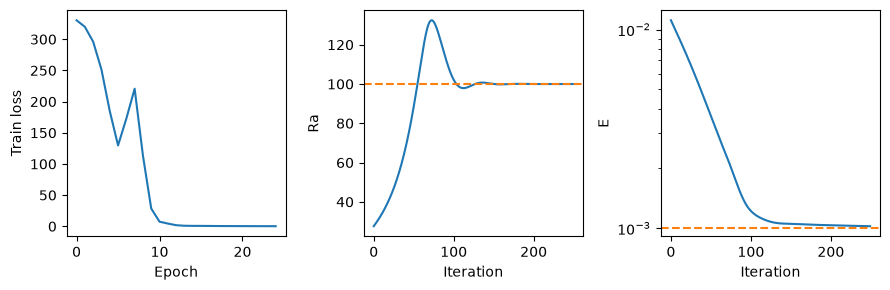

In [4]:
fig, axs = plt.subplots(figsize=(9, 3), ncols=3)

axs[0].plot(train_loss)
axs[0].set_ylabel("Train loss")
axs[0].set_xlabel("Epoch")
axs[1].plot(Ra_train)
axs[1].axhline(100, color="tab:orange", linestyle="--")
axs[1].set_ylabel("Ra")
axs[1].set_xlabel("Iteration")
axs[2].semilogy(E_train)
axs[2].axhline(1e-3, color="tab:orange", linestyle="--")
axs[2].set_ylabel("E")
axs[2].set_xlabel("Iteration")

fig.tight_layout()
plt.show()